In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/lotan.amit/WhatDoLLMsWant


# Synthetic cars — the ranking graphs of `real_laptops_trends` (2026-11-14)

The rank figures of [real_laptops_trends.ipynb](real_laptops_trends.ipynb) (F1r, F2r, F4r), rebuilt on
`data/synthetic_cars/`: 120 cars, 3 models, 4 tracks. Same look, same rank (one free utility per car, OLS on the
margins).

A **path** here is a track: no contract, then its four requests added one at a time (5 points, not 3).
With up to four requests a car can meet many different sets of them, so the colour is the **number** of
requests it meets, not which ones:

| colour | meaning |
|---|---|
| purple | meets **every** request of the contract (as "meets both" on the laptops) |
| blue, light to dark | meets 1, 2 or 3 of them, but not all |
| gray | meets none |

- **F1c** — all 120 cars with their names, one model, one figure per track (only the luxury one is shown here)
- **F2c** — all 120 cars, tracks × models
- **F4c** — mean rank of the cars grouped by how many of the track's four requests they meet

## Setup

Loading, the fit and the plot helpers. Nothing to read here unless a figure looks wrong.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
from matplotlib.lines import Line2D

pd.set_option("display.width", 220)
SAVE, FIGDIR = True, "figs/synthetic_cars_trends"
os.makedirs(FIGDIR, exist_ok=True)

BASE, FRAME = "data/synthetic_cars", "car_shopping"
MODELS = [("qwen", "72"), ("gemma", "27"), ("olmo", "32")]
HEADLINE = ("qwen", "72")
FEATS = ["company", "color", "fuel", "transmission", "ownership", "horsepower"]
TRACKS = {                                                 # the four contract paths: requests in the order they are added
    "luxury": [("transmission", "automatic"), ("company", "BMW"), ("horsepower", "200 hp"), ("color", "black")],
    "economy": [("fuel", "petrol"), ("transmission", "manual"), ("horsepower", "100 hp"), ("company", "Honda")],
    "family": [("transmission", "automatic"), ("ownership", "private first owner"), ("company", "Toyota"),
               ("color", "white")],
    "work": [("fuel", "diesel"), ("horsepower", "150 hp"), ("company", "Ford"), ("ownership", "ex-lease")],
}
OWN = {"private first owner": "1st owner", "private second owner": "2nd owner", "private third owner": "3rd owner"}

ITEMS = pd.read_csv(f"{BASE}/design/items.csv").set_index("id")
IDS = list(ITEMS.index)
N = len(IDS)
POS = {i: k for k, i in enumerate(IDS)}
LVL = {i: dict(ITEMS.loc[i, FEATS]) for i in IDS}

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": True,
    "grid.color": "#e8e7e3", "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
# purple and gray as in real_laptops_trends ("meets both" / "meets none"); one blue ramp for "meets some"
PURPLE, GRAY = "#4a3aa7", "#c9c8c4"
SOME = {1: "#b7d3f6", 2: "#6da7ec", 3: "#2a78d6"}


def name(m):
    return f"{m[0]}-{m[1]}B"


def save(fig, fname, dpi=None):
    if SAVE:
        fig.savefig(os.path.join(FIGDIR, fname + ".png"), facecolor=SURFACE, dpi=dpi)


def cid_of(con):
    return "+".join(f"{f}={v}" for f, v in sorted(con.items())) or "none"


def n_met(lvl, con):
    """How many requests of contract `con` this car meets."""
    return sum(lvl[f] == v for f, v in con.items())


def colour(lvl, con):
    k = n_met(lvl, con)
    return GRAY if k == 0 else PURPLE if k == len(con) else SOME[k]


def short(i):
    r = ITEMS.loc[i]
    return f"{r.company} {r.color} {r.fuel} {r.transmission[:4]} {r.horsepower.replace(' hp', '')} {OWN.get(r.ownership, r.ownership)}"

In [3]:
def load():
    """Complete runs only: config.json without scores.csv, or with too few rows, is a dead job."""
    R = {}
    for r in sorted(os.listdir(BASE)):
        cf, sc = f"{BASE}/{r}/config.json", f"{BASE}/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue
        c = json.load(open(cf))
        d = pd.read_csv(sc)
        if c["frame"]["name"] != FRAME or len(d) != c["n_rows"]:
            continue
        key = (c["model_family"], str(c["model_size"]), c["constraints_id"])
        assert key not in R, f"two complete runs share {key}"
        R[key] = d
    return R


RUNS = load()
CIDS = sorted({k[2] for k in RUNS})
assert len(RUNS) == len(MODELS) * 28 and all((*m, c) in RUNS for m in MODELS for c in CIDS)
print(len(RUNS), "runs =", len(MODELS), "models x", len(CIDS), "contracts")


def item_fit(d):
    """BT with ONE free utility per car, by OLS on the margins: m = gamma + u_a - u_b (as in
    real_laptops_trends). Works on the sampled-pair runs too. Returns (utilities, mean 0; gamma; R2)."""
    a, b = d.a_id.map(POS).values, d.b_id.map(POS).values
    n = len(d)
    X = np.zeros((n, N))
    X[np.arange(n), a] += 1
    X[np.arange(n), b] -= 1
    X = np.column_stack([np.ones(n), X[:, 1:]])           # drop one car: it is the reference
    y = (d.score_a - d.score_b).values
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    u = np.r_[0.0, beta[1:]]
    r2 = 1 - ((y - X @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return pd.Series(u - u.mean(), index=IDS), beta[0], r2


def rank_desc(x, ties="first"):
    return pd.Series(x).rank(ascending=False, method=ties)


UTIL, R2_ITEM = {}, {}
for key, d in RUNS.items():
    UTIL[key], _, R2_ITEM[key] = item_fit(d)
RANK = {m: pd.DataFrame({c: rank_desc(UTIL[(*m, c)]) for c in CIDS}) for m in MODELS}     # 1 = most preferred
print("R2 of the per-car fit, median over the 28 contracts:",
      {name(m): round(float(np.median([R2_ITEM[(*m, c)] for c in CIDS])), 3) for m in MODELS})

84 runs = 3 models x 28 contracts
R2 of the per-car fit, median over the 28 contracts: {'qwen-72B': 0.927, 'gemma-27B': 0.796, 'olmo-32B': 0.922}


## 0 — Can we trust ranks from the sampled pairs?

The 12 compound contracts were scored on about 825 of the 7,140 pairs (500 shared pairs + every pair with one
of the track's 3 target cars). Test on the 16 runs that have all pairs: fit the cars on a track's pairs only
and compare with the fit on everything.

In [4]:
rows = []
for t in TRACKS:
    P = pd.read_csv(f"{BASE}/design/pairs_{t}.csv").values
    keys = set(map(tuple, P)) | set(map(tuple, P[:, ::-1]))
    tg = ITEMS.index[(ITEMS.part == "target") & (ITEMS.track == t)]
    for m in MODELS:
        for c in [c for c in CIDS if "+" not in c]:
            d = RUNS[(*m, c)]
            sub = d[[k in keys for k in zip(d.a_id, d.b_id)]]
            full, part = RANK[m][c], rank_desc(item_fit(sub)[0])
            err = (part - full).abs()
            rows.append({"model": name(m), "Spearman": st.spearmanr(part, full)[0],
                         "median rank error": err.drop(tg).median(), "90% of cars within": err.drop(tg).quantile(0.9),
                         "target cars, mean error": err[tg].mean()})
CHECK = pd.DataFrame(rows).groupby("model", sort=False).mean().round(2)
print("rank from a track's pairs vs rank from all pairs (mean over 16 contracts x 4 tracks; ranks are 1-120)")
CHECK

rank from a track's pairs vs rank from all pairs (mean over 16 contracts x 4 tracks; ranks are 1-120)


,Spearman,median rank error,90% of cars within,"target cars, mean error"
model,,,,
qwen-72B,0.98,3.27,11.11,1.65
gemma-27B,0.97,4.22,12.89,1.99
olmo-32B,0.99,2.45,7.84,1.32


In [5]:
def make_path(t):
    """The contract path of track t: no contract, then its requests one at a time."""
    cons = [dict(TRACKS[t][:k]) for k in range(len(TRACKS[t]) + 1)]
    lab = ["no contract"] + [("" if k == 0 else "+ ") + OWN.get(v, v) for k, (f, v) in enumerate(TRACKS[t])]
    return dict(track=t, ids=[cid_of(c) for c in cons], cons=cons, lab=lab, title=f"{t} track")


PATHS = {t: make_path(t) for t in TRACKS}


def spread(ys, gap):
    """Push label positions apart so that no two are closer than `gap`."""
    out = np.array(ys, dtype=float)
    order = np.argsort(out)
    for a, b in zip(order[:-1], order[1:]):
        out[b] = max(out[b], out[a] + gap)
    return out


def bump(ax, R, path, label_of=None, fs=7):
    """One line per car; x = contract on the path, y = rank (1 on top). Segment i -> i+1 is coloured by how
    many requests of contract i+1 the car meets; the point at i by those of contract i. Cars that meet the
    full contract get a bold label."""
    R, CONS = R[path["ids"]], path["cons"]
    x = np.arange(len(CONS))
    labels = label_of is not None
    ms = 4 if labels else 2.2
    lw = (1.6, 0.9) if labels else (1.1, 0.6)             # (coloured, gray)
    for i_car, row in R.iterrows():
        lvl, y = LVL[i_car], row.values
        for i in range(len(CONS) - 1):
            c = colour(lvl, CONS[i + 1])
            ax.plot(x[i:i + 2], y[i:i + 2], color=c, lw=lw[c == GRAY], solid_capstyle="round",
                    zorder=1 if c == GRAY else 4 if c == PURPLE else 2)
        for i in range(len(CONS)):
            ax.plot(x[i], y[i], ls="", marker="o", color=colour(lvl, CONS[i]), ms=ms, mew=0, zorder=5)
    for side in (("left", "right") if labels else ()):
        xi, ha, off = (0, "right", -0.07) if side == "left" else (x[-1], "left", 0.07)
        for i_car, yy in zip(R.index, R.iloc[:, xi].values):
            k = n_met(LVL[i_car], CONS[-1])
            ax.text(xi + off, yy, label_of(i_car), ha=ha, va="center", fontsize=fs,
                    color=INK if k else INK_MUTED, fontweight="bold" if k == len(CONS[-1]) else "normal")
    ax.set_xticks(x, path["lab"])
    ax.set_xlim(-(1.15 if labels else 0.08), x[-1] + (1.15 if labels else 0.08))
    ax.set_ylim(N + 1.2, 0.2)
    ax.set_yticks([1] + list(range(20, N + 1, 20)))
    ax.grid(axis="x", visible=False)


def legend_handles(grouped=False):
    if grouped:
        return ([Line2D([], [], color=PURPLE, lw=2.2, label="meets all 4 requests of the track")]
                + [Line2D([], [], color=SOME[k], lw=2.2, label=f"meets {k} of the 4") for k in (3, 2, 1)]
                + [Line2D([], [], color=GRAY, lw=2.2, label="meets none")])
    return ([Line2D([], [], color=PURPLE, lw=2.2, label="meets every request of the contract")]
            + [Line2D([], [], color=SOME[k], lw=2.2, label=f"meets {k}, not all") for k in (3, 2, 1)]
            + [Line2D([], [], color=GRAY, lw=2.2, label="meets none")])


def group_rank(m, path):
    """Mean rank of the cars in each group = how many of the track's 4 requests the car meets (0-4)."""
    g = pd.Series({i: n_met(LVL[i], path["cons"][-1]) for i in IDS})
    G = RANK[m][path["ids"]].groupby(g).mean()
    G["n"] = g.value_counts()
    return G


def bump_groups(ax, G, path, fs=7.5):
    """One line per group, in the group's colour, labelled on the right."""
    x = np.arange(len(path["ids"]))
    K = len(path["cons"][-1])
    col = {0: GRAY, K: PURPLE, **{k: SOME[k] for k in range(1, K)}}
    ys = spread(G[path["ids"][-1]].values, 4.5)
    for (k, row), yy in zip(G.iterrows(), ys):
        ax.plot(x, row[path["ids"]].values, "o-", color=col[k], lw=2.2 if k else 1.2, ms=5, zorder=2 + k)
        lab = "all 4" if k == K else "none" if k == 0 else f"{k} of 4"
        ax.text(x[-1] + 0.1, yy, f"{lab} (n={int(row.n)})", ha="left", va="center", fontsize=fs,
                color=INK if k else INK_MUTED, fontweight="bold" if k == K else "normal")
    ax.set_xticks(x, path["lab"])
    ax.set_xlim(-0.1, x[-1] + 1.0)
    ax.set_ylim(N + 1.2, 0.2)
    ax.set_yticks([1] + list(range(20, N + 1, 20)))
    ax.grid(axis="x", visible=False)


def path_grid(title, fname, grouped=False):
    """Rows = tracks, columns = models. grouped=False: all 120 cars; True: the 5 groups, labelled."""
    fig, axes = plt.subplots(len(PATHS), 3, figsize=(14, (3.6 if grouped else 4.6) * len(PATHS)),
                             sharey=True, squeeze=False)
    for r, path in enumerate(PATHS.values()):
        for ax, m in zip(axes[r], MODELS):
            if grouped:
                bump_groups(ax, group_rank(m, path), path)
            else:
                bump(ax, RANK[m], path)
            ax.set_title(f"{name(m)} - {path['title']}", loc="left", fontsize=10, fontweight="bold")
            ax.set_xticks(range(len(path["ids"])), path["lab"], fontsize=8.5)
        axes[r, 0].set_ylabel(f"mean rank of the group (of {N})" if grouped else "rank (1 = most preferred)")
    top = 0.955
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.legend(handles=legend_handles(grouped), loc="lower left", ncol=5, bbox_to_anchor=(0.01, top + 0.003),
               frameon=False, fontsize=9)
    fig.suptitle(title, x=0.01, y=1.0, ha="left", fontweight="bold")
    save(fig, fname, dpi=None if grouped else 130)
    plt.show()

# Graph 1 — car rank along the contract path

## F1c — all 120 cars with their names, one model, one figure per track

A label reads: company, color, fuel, transmission, horsepower, ownership. Bold = the car meets all four
requests of the track (its 3 target cars).

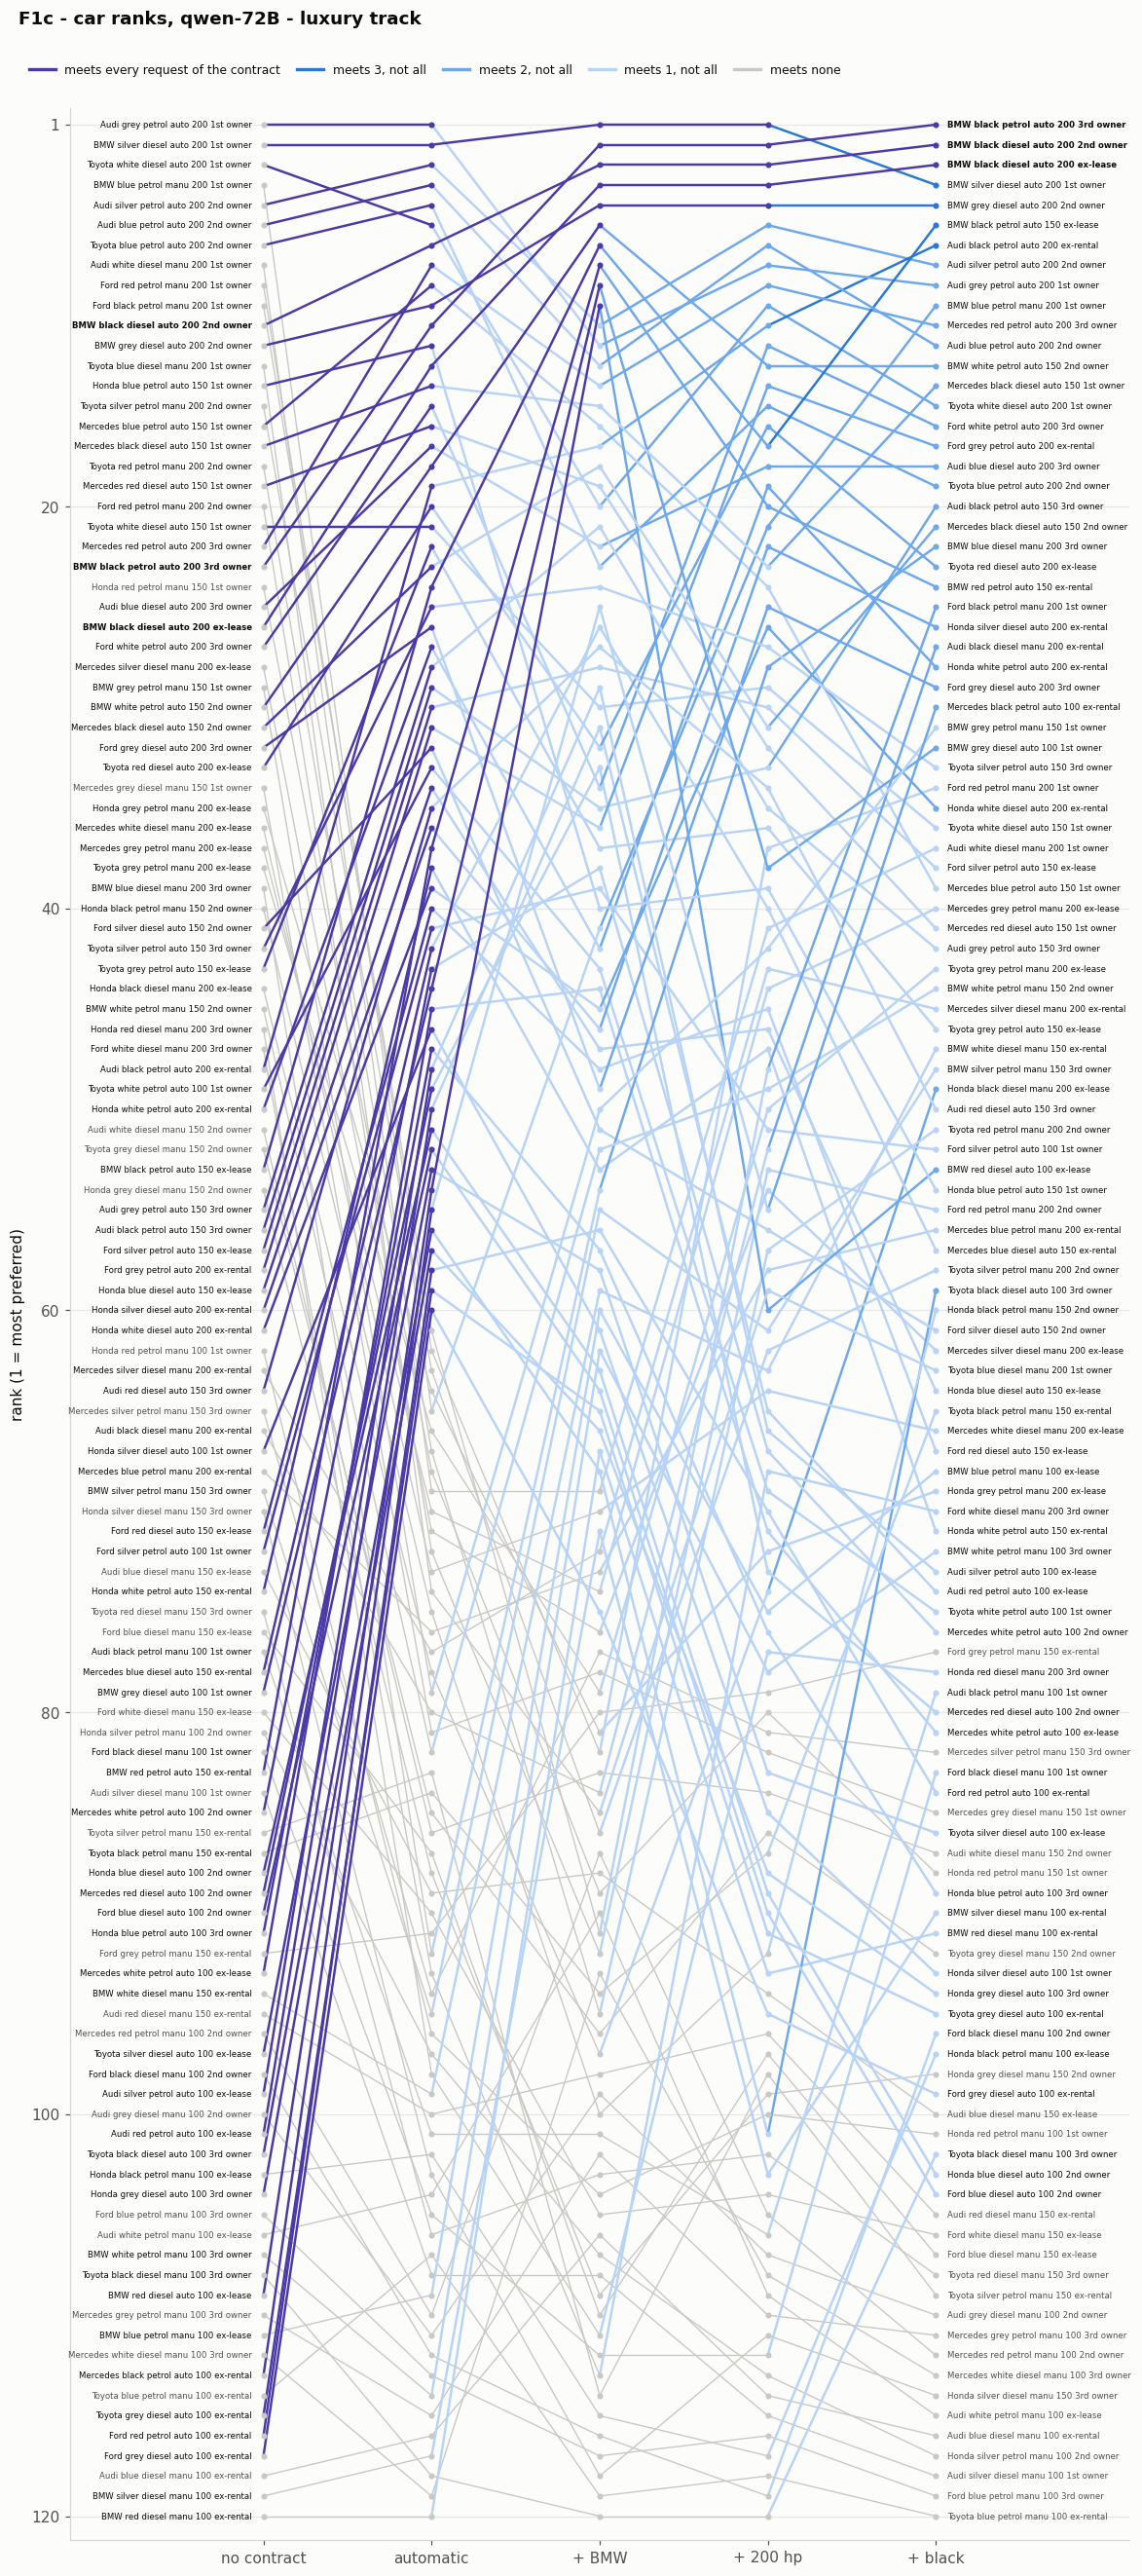

saved: ['F1c_rank_qwen-72B_luxury.png', 'F1c_rank_qwen-72B_economy.png', 'F1c_rank_qwen-72B_family.png', 'F1c_rank_qwen-72B_work.png']


In [6]:
for t, path in PATHS.items():
    fig, ax = plt.subplots(figsize=(11, 24))
    bump(ax, RANK[HEADLINE], path, label_of=short, fs=5.6)
    ax.set_ylabel("rank (1 = most preferred)")
    top = 0.968
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.legend(handles=legend_handles(), loc="lower left", ncol=5, bbox_to_anchor=(0.02, top + 0.002), frameon=False,
               fontsize=8, handlelength=2.2, columnspacing=1.4)
    fig.suptitle(f"F1c - car ranks, {name(HEADLINE)} - {path['title']}", x=0.02, y=1.0, ha="left", fontweight="bold")
    save(fig, f"F1c_rank_{name(HEADLINE)}_{t}", dpi=130)
    if t == "luxury":
        plt.show()                                  # the other three are saved, not shown: they are big
    else:
        plt.close(fig)
print("saved:", [f"F1c_rank_{name(HEADLINE)}_{t}.png" for t in PATHS])

## F2c — all 120 cars, the four tracks and the three models

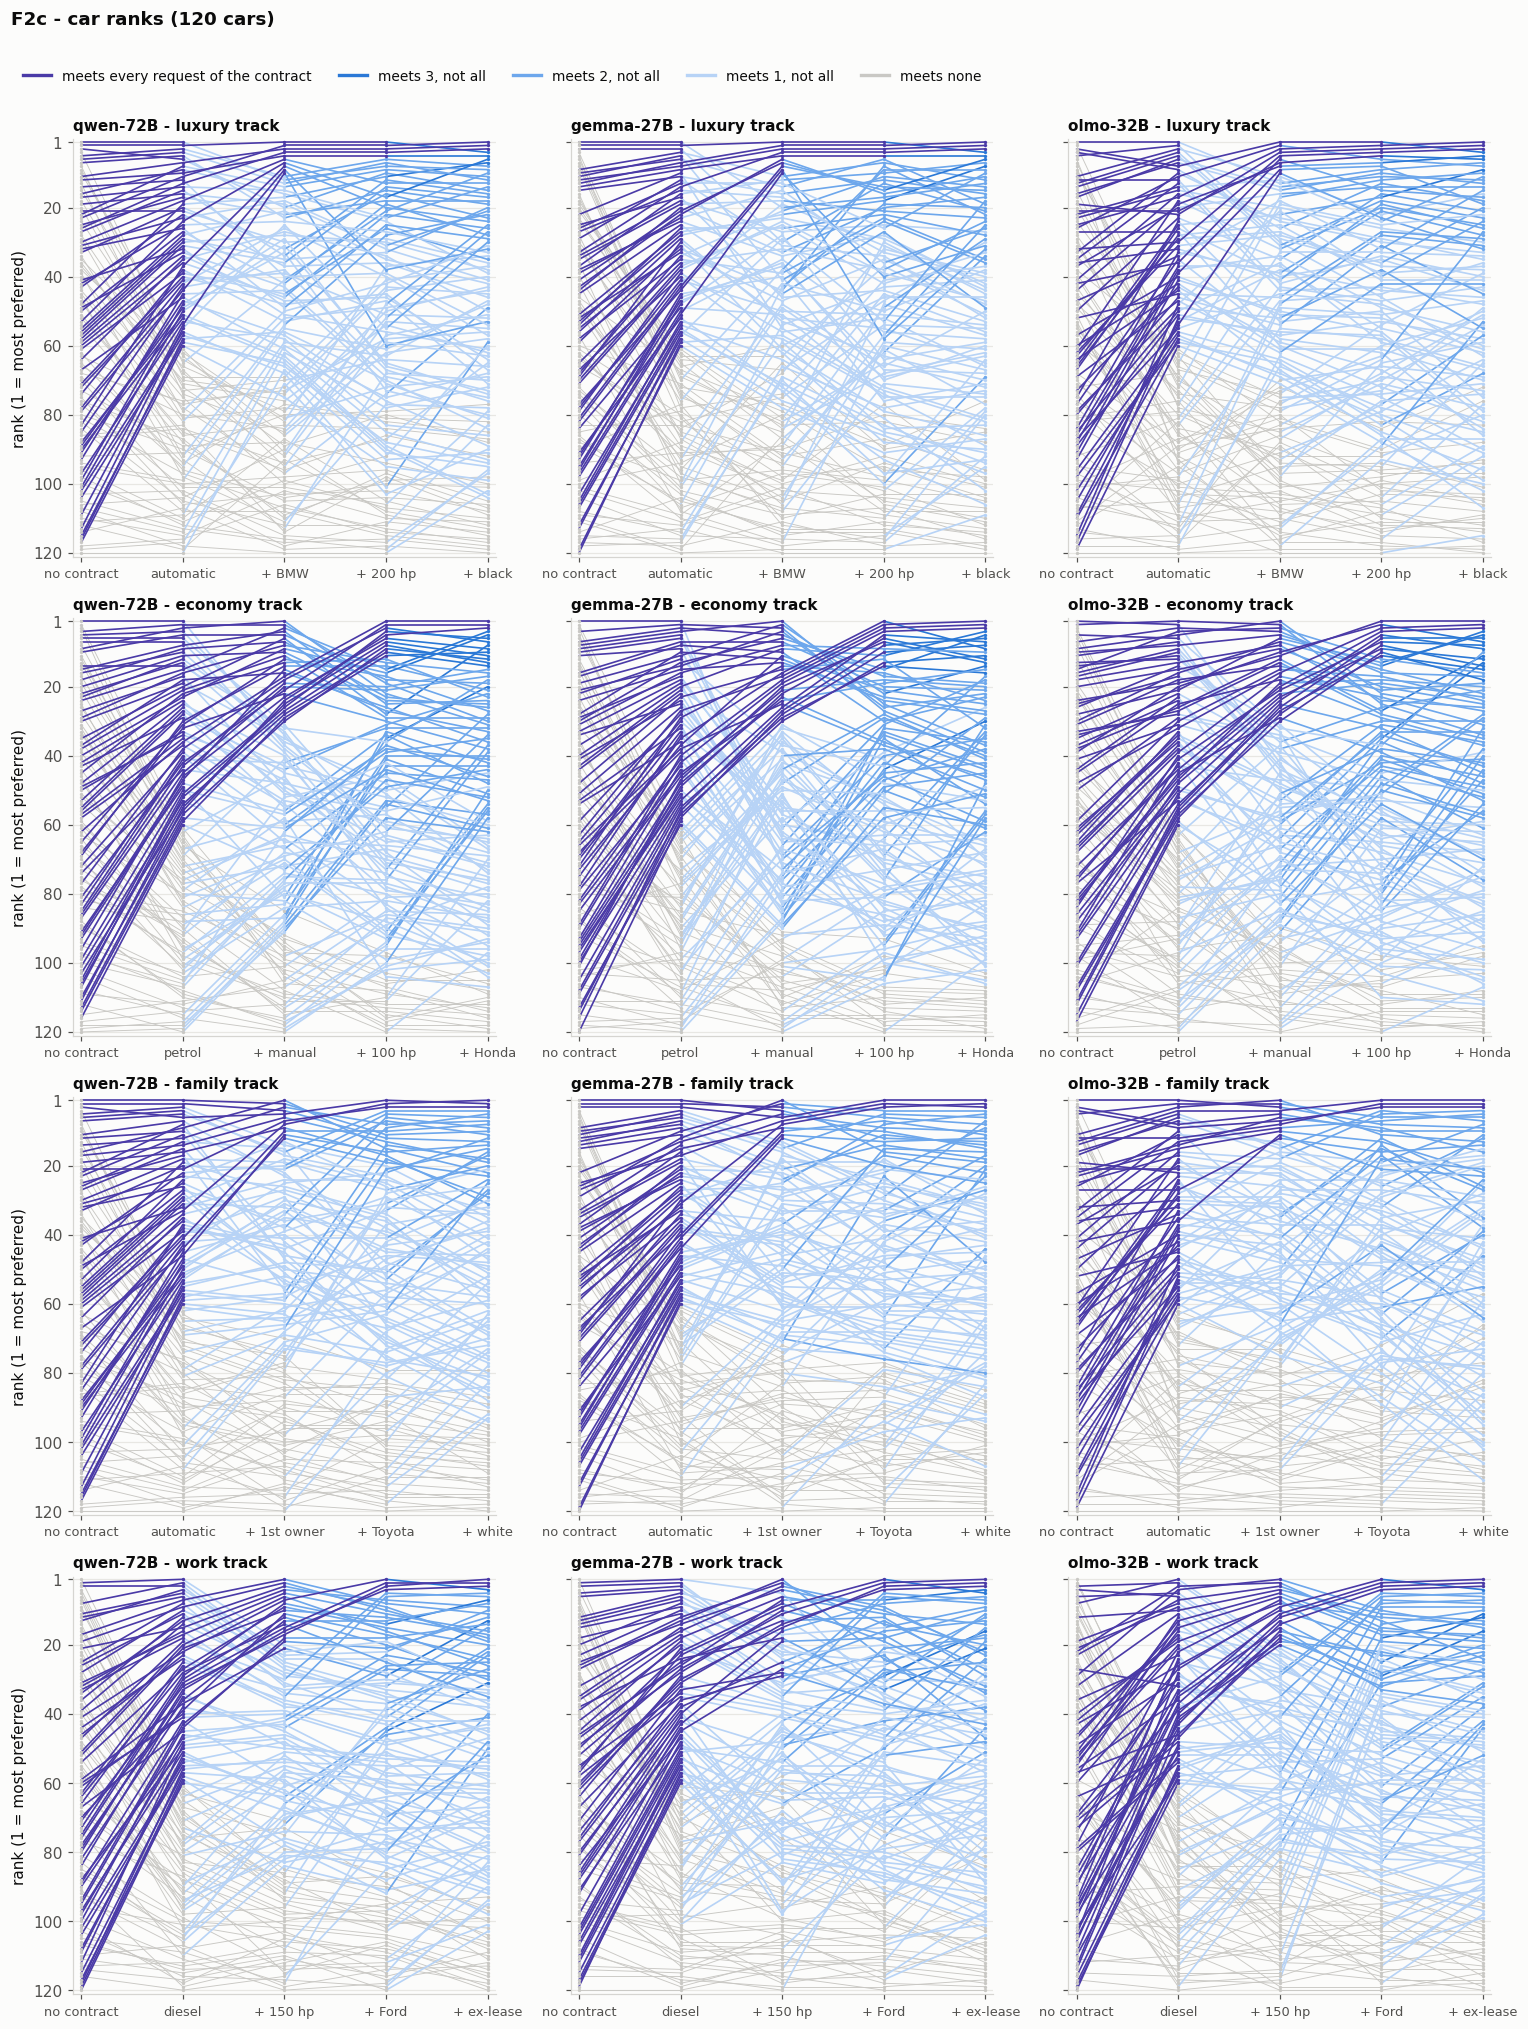

In [7]:
path_grid("F2c - car ranks (120 cars)", "F2c_rank_grid")

## F4c — grouped by how many of the track's requests the car meets

One line = the mean rank of the cars that meet exactly that many of the track's four requests. The table gives
the same numbers for the cars that meet all four (the 3 target cars), and how many of them are in the top 3.

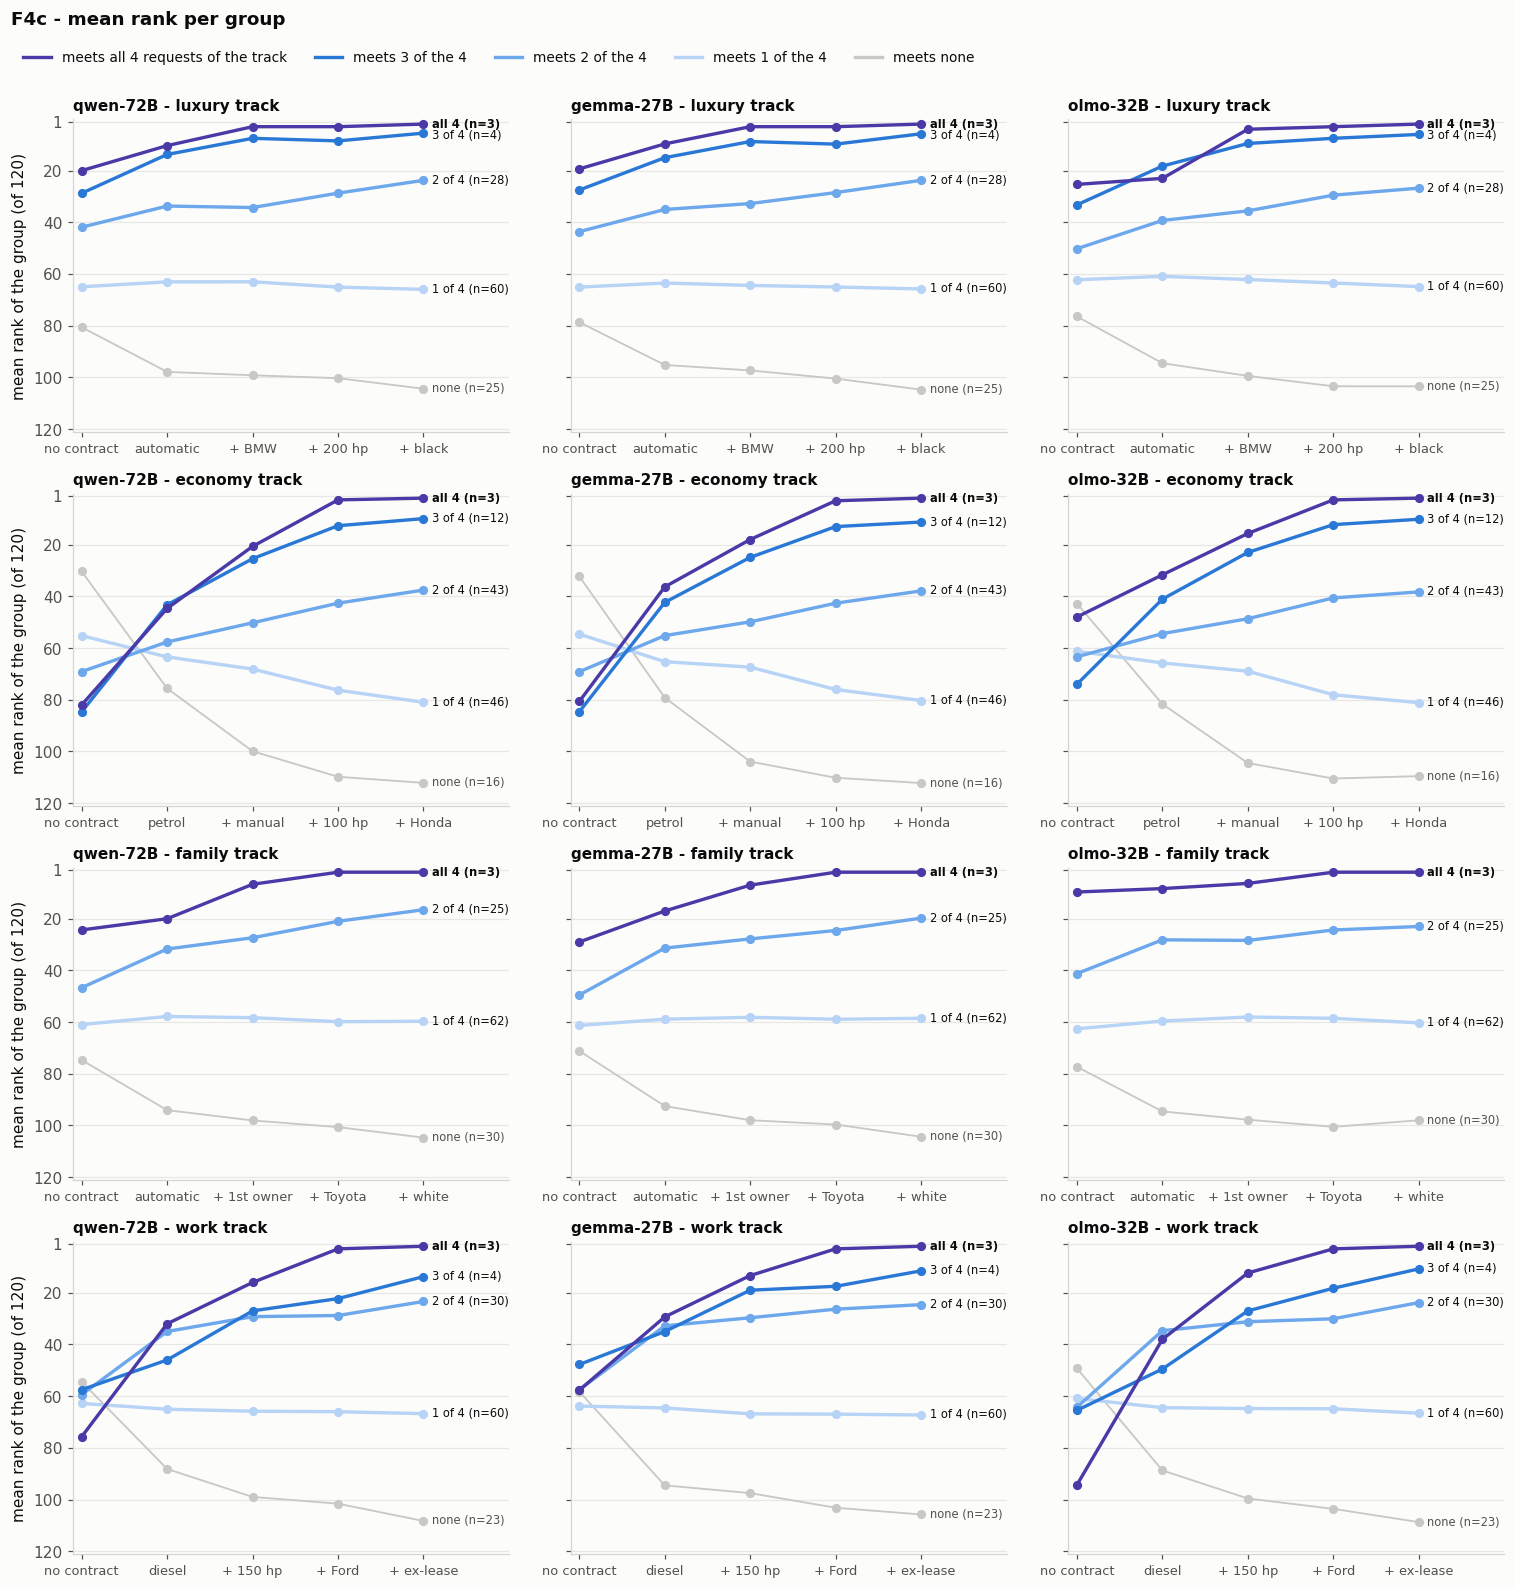

the 3 cars that meet all four requests: mean rank at each step (best possible: 2.0), and how many are in the top 3


,track,model,step 0,step 1,step 2,step 3,step 4,"in top 3, step 0","in top 3, step 1","in top 3, step 2","in top 3, step 3","in top 3, step 4"
4,luxury,qwen-72B,20.0,10.3,3.0,3.0,2.0,0.0,0.0,2.0,2.0,3.0
9,luxury,gemma-27B,19.3,9.7,3.0,3.0,2.0,0.0,0.0,2.0,2.0,3.0
14,luxury,olmo-32B,25.3,23.0,4.0,3.0,2.0,0.0,0.0,1.0,2.0,3.0
19,economy,qwen-72B,82.0,44.7,20.7,2.7,2.0,0.0,0.0,0.0,2.0,3.0
24,economy,gemma-27B,80.7,36.3,18.0,3.0,2.0,0.0,0.0,0.0,2.0,3.0
29,economy,olmo-32B,48.0,31.7,15.7,2.7,2.0,0.0,0.0,0.0,2.0,3.0
33,family,qwen-72B,24.3,20.0,6.7,2.0,2.0,1.0,0.0,0.0,3.0,3.0
37,family,gemma-27B,29.0,17.0,7.0,2.0,2.0,1.0,1.0,0.0,3.0,3.0
41,family,olmo-32B,9.7,8.3,6.3,2.0,2.0,0.0,0.0,0.0,3.0,3.0
46,work,qwen-72B,75.7,32.0,16.0,3.0,2.0,0.0,0.0,0.0,2.0,3.0


In [8]:
path_grid("F4c - mean rank per group", "F4c_rank_by_group_grid", grouped=True)

rows = []
for t, path in PATHS.items():
    all4 = [i for i in IDS if n_met(LVL[i], path["cons"][-1]) == 4]
    for m in MODELS:
        G = group_rank(m, path)
        for k in G.index:
            rows.append({"track": t, "model": name(m), "requests met": k, "n": int(G.loc[k, "n"]),
                         **{f"step {s}": G.loc[k, c] for s, c in enumerate(path["ids"])}})
        rows[-1].update({f"in top 3, step {s}": int(RANK[m][c].loc[all4].le(3).sum()) for s, c in enumerate(path["ids"])})
GT = pd.DataFrame(rows)
GT.to_csv(os.path.join(FIGDIR, "F4c_rank_by_group.csv"), index=False)
print("the 3 cars that meet all four requests: mean rank at each step (best possible: 2.0), and how many are in the top 3")
GT[GT["requests met"] == 4].drop(columns=["requests met", "n"]).round(1)

# Graph 5 — the starting point, and what happens to the colour preference

## F12c — feature weights next to the positional bias, no contract

The additive fit (`src/bt.py`) on the six features, one panel per model. Weights are centred inside each
feature, so 0 = the average level. **γ** = how much being shown first moves the answer; positive = the model
favours the first slot. Each panel has its own y scale: the models differ in how loud they are.

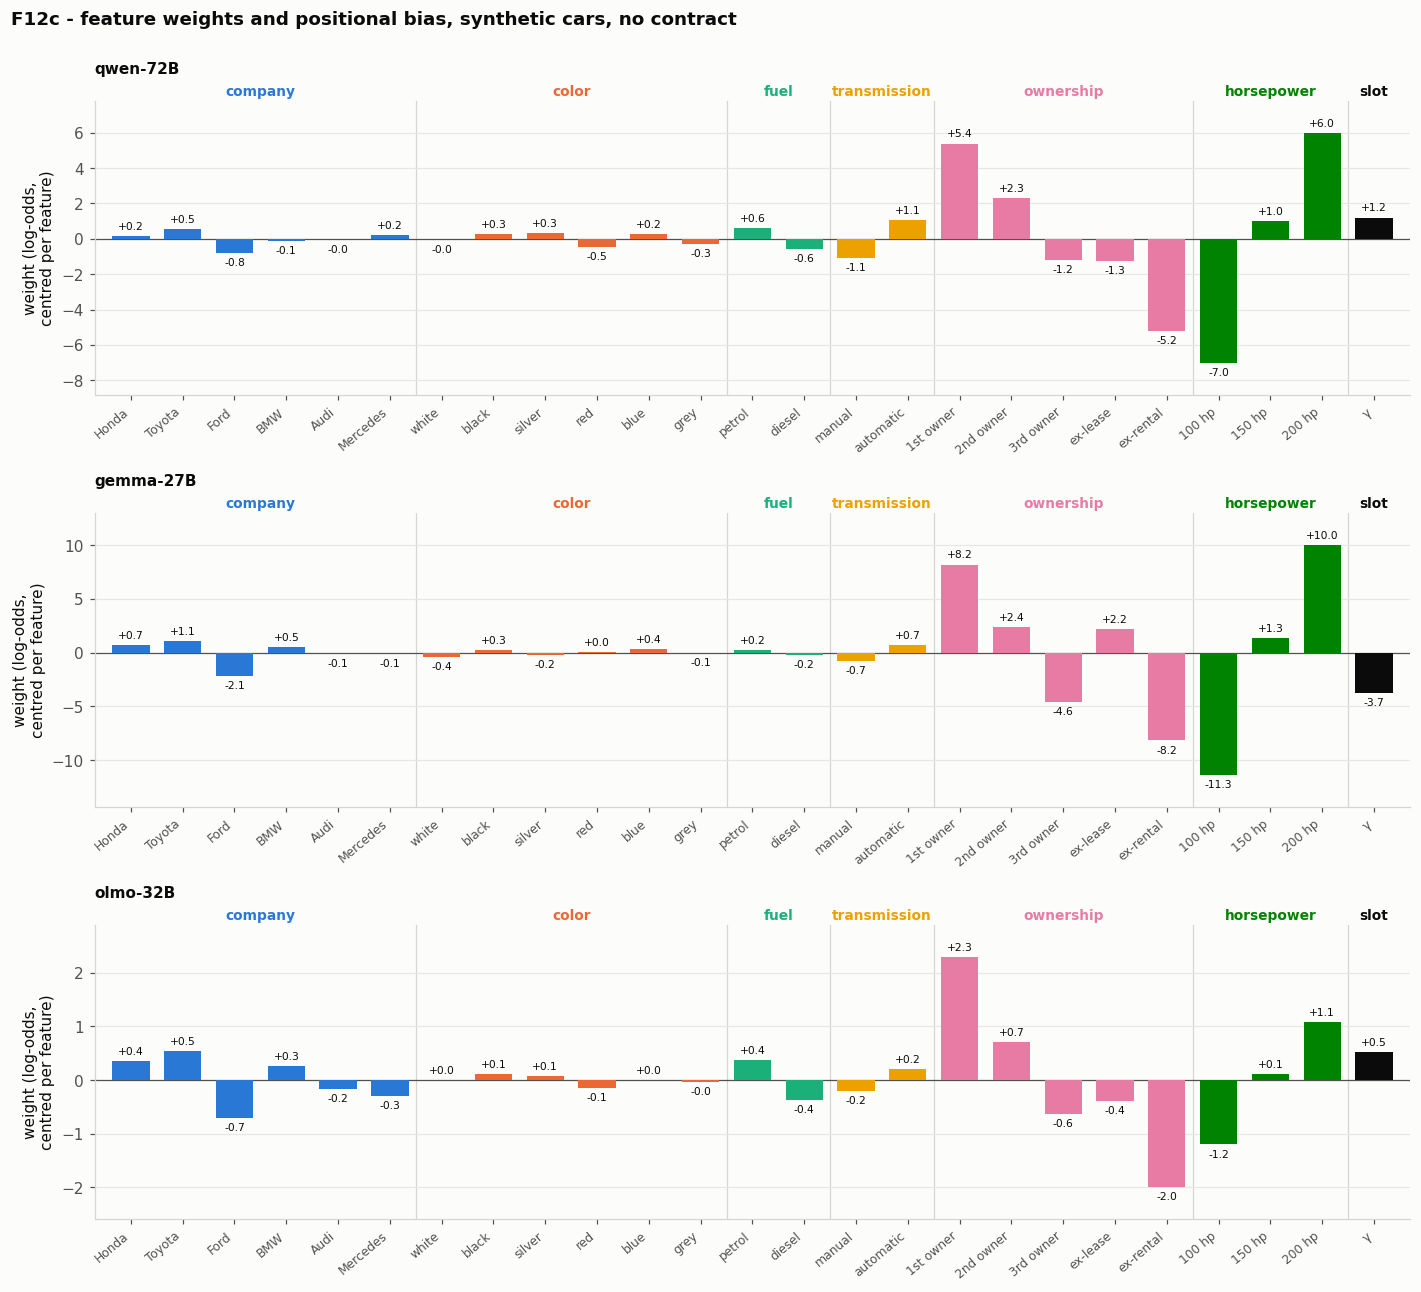

range = best level minus worst level of the feature


,model,range company,range color,range fuel,range transmission,range ownership,range horsepower,gamma,R2 additive (rows),R2 per-car (rows)
0,qwen-72B,1.35,0.81,1.18,2.14,10.61,12.97,1.20,0.81,0.82
1,gemma-27B,3.20,0.76,0.47,1.46,16.35,21.31,-3.75,0.76,0.77
2,olmo-32B,1.25,0.26,0.73,0.42,4.29,2.29,0.52,0.82,0.83


In [9]:
from src.bt import FeatureBT

LEVELS = {
    "company": ["Honda", "Toyota", "Ford", "BMW", "Audi", "Mercedes"],
    "color": ["white", "black", "silver", "red", "blue", "grey"],
    "fuel": ["petrol", "diesel"],
    "transmission": ["manual", "automatic"],
    "ownership": ["private first owner", "private second owner", "private third owner", "ex-lease", "ex-rental"],
    "horsepower": ["100 hp", "150 hp", "200 hp"],
}
FEATURE_COLOR = dict(zip(FEATS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
FCOLS = [f"{s}_{f}" for s in "ab" for f in FEATS] + ["score_a", "score_b"]       # FeatureBT fits every a_* column: a_id must go
_sh = pd.read_csv(f"{BASE}/design/compound_pairs.csv").values
SHARED = set(map(tuple, _sh)) | set(map(tuple, _sh[:, ::-1]))                    # the 500 shared pairs, both orders


def additive_fit(d, shared=False, control=None):
    """The additive fit. shared=True: on the 500 shared pairs only. control = a contract {feature: level}:
    the fit also gets "how many of its requests the car meets" as one more feature (see F13c for why)."""
    cols = FCOLS
    if shared:
        d = d[[k in SHARED for k in zip(d.a_id, d.b_id)]]
    if control:
        met = pd.Series({i: str(n_met(LVL[i], control)) for i in IDS})
        d = d.assign(a_met=d.a_id.map(met).values, b_met=d.b_id.map(met).values)
        cols = FCOLS[:-2] + ["a_met", "b_met"] + FCOLS[-2:]
    return FeatureBT(r2_warn=None).fit(d[cols])


FITS = {(m, c): additive_fit(RUNS[(*m, c)]) for m in MODELS for c in CIDS if "+" not in c}     # the 16 runs with all pairs
lv = [(ft, l) for ft in FEATS for l in LEVELS[ft]]
fig, axes = plt.subplots(len(MODELS), 1, figsize=(13, 3.9 * len(MODELS)))
rows = []
for ax, m in zip(axes, MODELS):
    f = FITS[(m, "none")]
    vals = [f.weights_[ft][l] for ft, l in lv] + [f.gamma_]
    cols = [FEATURE_COLOR[ft] for ft, _ in lv] + [INK]
    x = np.arange(len(vals))
    ax.bar(x, vals, 0.72, color=cols, zorder=2)
    ax.axhline(0, color=INK_MUTED, lw=0.8, zorder=1)
    pad = 0.02 * (max(vals) - min(vals))
    for xi, v in zip(x, vals):
        ax.text(xi, v + (pad if v >= 0 else -pad), f"{v:+.1f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=7)
    ax.set_xticks(x, [OWN.get(l, l) for _, l in lv] + ["γ"], rotation=40, ha="right", fontsize=8)
    for ft in FEATS:
        idx = [i for i, (ff, _) in enumerate(lv) if ff == ft]
        ax.text(np.mean(idx), 1.01, ft, transform=ax.get_xaxis_transform(), ha="center", va="bottom",
                fontweight="bold", fontsize=9, color=FEATURE_COLOR[ft])
        if idx[0] > 0:
            ax.axvline(idx[0] - 0.5, color="#d6d5d1", lw=0.8, zorder=0)
    ax.axvline(len(lv) - 0.5, color="#d6d5d1", lw=0.8, zorder=0)
    ax.text(len(lv), 1.01, "slot", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontweight="bold", fontsize=9)
    ax.margins(y=0.14)
    ax.set_xlim(-0.7, len(vals) - 0.3)
    ax.grid(axis="x", visible=False)
    ax.set_title(name(m), loc="left", fontsize=10, fontweight="bold", pad=18)
    ax.set_ylabel("weight (log-odds,\ncentred per feature)")
    rows.append({"model": name(m), **{f"range {ft}": f.range(ft) for ft in FEATS}, "gamma": f.gamma_,
                 "R2 additive (rows)": f.r2_, "R2 per-car (rows)": R2_ITEM[(*m, "none")]})
fig.suptitle("F12c - feature weights and positional bias, synthetic cars, no contract", x=0.01, y=1.0, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "F12c_feature_weights")
plt.show()
W0 = pd.DataFrame(rows)
print("range = best level minus worst level of the feature")
W0.round(2)

## F13c — the colour weights across the contracts that do not mention colour

Does the colour order of "no contract" survive when the user asks for something else? One line per colour, drawn
in that colour. The small number above each contract is the **Spearman** correlation between its six colour
weights and those of "no contract" in the same panel (1 = same order, 0 = unrelated, −1 = reversed).

- **Left: the 13 single requests** (all 7,140 pairs).
- **Right: the 10 compound contracts** without a colour. Two things are different here, both to keep the colour
  weights from picking up wins that come from meeting the contract:
  - every fit, also the "no contract" one, uses only the **500 shared pairs**. The compound runs also hold every
    pair with a target car, and the target cars of a track share a colour (luxury: all black, family: all white);
  - the fit gets one more term: **how many of the contract's requests the car meets**. Few cars meet a compound
    contract, and their colours are not balanced (only 3 of the 30 petrol + manual cars are white). Without the
    term, white drops by 2.6 under "petrol + manual" for qwen-72B; with it, by 0.7.

  The right panel is weaker evidence than the left one: 1,000 rows per fit, and a handful of cars per colour
  among those that meet a contract.

The four contracts that ask for a colour are left out (`black`, `white`, luxury 4, family 4).

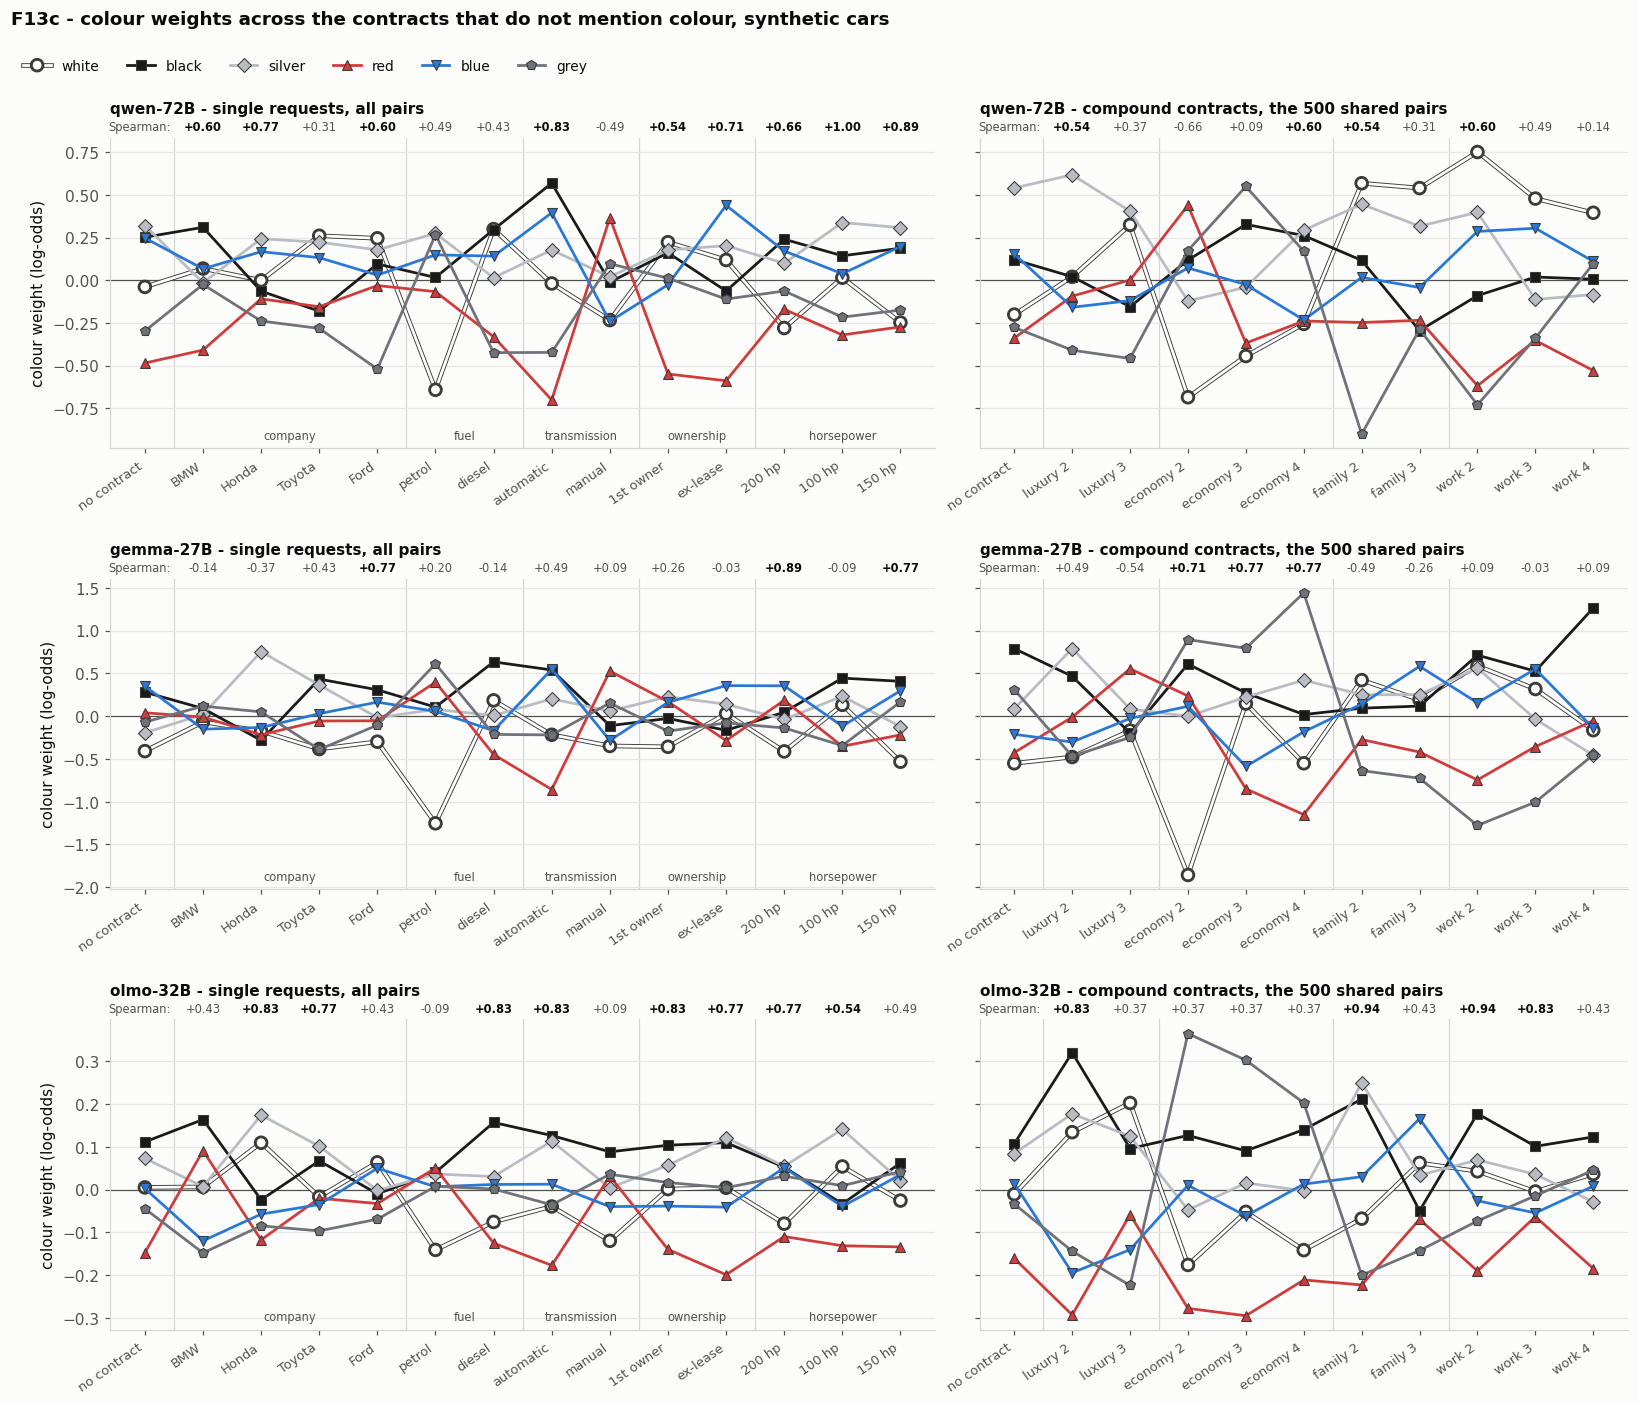

colour order against 'no contract' (same pairs)


contracts  spearman_median  spearman_min  spearman_max  spearman_above_half  pearson_median  same_top  same_bottom  range_median
model     kind                                                                                                                                      
qwen-72B  single           13             0.60         -0.49          1.00                    9            0.75       4.0          6.0          0.72
          compound         10             0.43         -0.66          0.60                    4            0.38       3.0          2.0          0.96
gemma-27B single           13             0.20         -0.37          0.89                    3            0.48       3.0          6.0          0.82
          compound         10             0.09         -0.54          0.77                    3            0.28       2.0          2.0          1.60
olmo-32B  single           13             0.77         -0.09          0.83                    8            0.67       6.0          8.0          0.24
          compound         10             0.43          0.37          0.94                    4            0.68       4.0          8.0          0.42

In [10]:
import matplotlib.patheffects as pe

COLOR_HEX = {"white": "#ffffff", "black": "#1a1a1a", "silver": "#b9bcc2", "red": "#d03b3b", "blue": "#2a78d6", "grey": "#6f7278"}
COLOR_MARK = {"white": "o", "black": "s", "silver": "D", "red": "^", "blue": "v", "grey": "p"}
CLV = LEVELS["color"]

SINGLE_X = [("no contract", "none", "")]                               # (tick label, constraints_id, group)
for ft in ("company", "fuel", "transmission", "ownership", "horsepower"):
    for fv in dict.fromkeys(fv for t in TRACKS.values() for fv in t):
        if fv[0] == ft:
            SINGLE_X.append((OWN.get(fv[1], fv[1]), cid_of(dict([fv])), ft))
COMP_X = [("no contract", "none", "")]
for t in TRACKS:
    for k in (2, 3, 4):
        if "color" not in dict(TRACKS[t][:k]):
            COMP_X.append((f"{t} {k}", cid_of(dict(TRACKS[t][:k])), t))
FITS_SH = {(m, c): additive_fit(RUNS[(*m, c)], shared=True,
                                control=dict(p.split("=") for p in c.split("+")) if c != "none" else None)
           for m in MODELS for _, c, _ in COMP_X}


def colour_w(f):
    return np.array([f.weights_["color"][c] for c in CLV])


rows = []
fig, axes = plt.subplots(len(MODELS), 2, figsize=(15, 4.3 * len(MODELS)), squeeze=False,
                         gridspec_kw={"width_ratios": [len(SINGLE_X), len(COMP_X)], "wspace": 0.06})
for r, m in enumerate(MODELS):
    for ax, X, fits, what in ((axes[r, 0], SINGLE_X, FITS, "all pairs"), (axes[r, 1], COMP_X, FITS_SH, "500 shared pairs")):
        Wm = np.array([colour_w(fits[(m, c)]) for _, c, _ in X])            # contracts x colours
        x = np.arange(len(X))
        for j, c in enumerate(CLV):
            ax.plot(x, Wm[:, j], "-", marker=COLOR_MARK[c], color=COLOR_HEX[c], ms=6.5, lw=1.8, label=c,
                    markeredgecolor="#3a3a38", markeredgewidth=0.7, zorder=3,
                    path_effects=[pe.Stroke(linewidth=3.0, foreground="#3a3a38"), pe.Normal()] if c == "white" else None)
        ax.axhline(0, color=INK_MUTED, lw=0.8, zorder=1)
        for i, (lab, c, g) in enumerate(X):
            if i:
                rho, pear = st.spearmanr(Wm[i], Wm[0])[0], np.corrcoef(Wm[i], Wm[0])[0, 1]
                ax.text(i, 1.015, f"{rho:+.2f}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7.5,
                        color=INK if rho >= 0.5 else INK_MUTED, fontweight="bold" if rho >= 0.5 else "normal")
                rows.append({"model": name(m), "fit on": what, "kind": "single" if ax is axes[r, 0] else "compound",
                             "contract": lab, "constraints_id": c, "spearman": rho, "pearson": pear,
                             "same top colour": int(Wm[i].argmax() == Wm[0].argmax()),
                             "same bottom colour": int(Wm[i].argmin() == Wm[0].argmin()),
                             "range": Wm[i].max() - Wm[i].min(), **dict(zip(CLV, Wm[i]))})
            else:
                rows.append({"model": name(m), "fit on": what, "kind": "none", "contract": lab, "constraints_id": c,
                             "range": Wm[0].max() - Wm[0].min(), **dict(zip(CLV, Wm[0]))})
            if i and g != X[i - 1][2]:
                ax.axvline(i - 0.5, color="#d6d5d1", lw=0.8, zorder=0)
        ax.text(0.45, 1.015, "Spearman:", transform=ax.get_xaxis_transform(), ha="right", va="bottom", fontsize=7.5, color=INK_MUTED)
        for g in dict.fromkeys(g for _, _, g in X if g and ax is axes[r, 0]):      # feature names inside the left panel
            ax.text(np.mean([i for i, q in enumerate(X) if q[2] == g]), 0.02, g, transform=ax.get_xaxis_transform(),
                    ha="center", va="bottom", fontsize=7.5, color=INK_MUTED)
        ax.set_xticks(x, [lab for lab, _, _ in X], rotation=35, ha="right", fontsize=8.5)
        ax.set_xlim(-0.6, len(X) - 0.4)
        ax.grid(axis="x", visible=False)
        ax.set_title(f"{name(m)} - " + ("single requests, all pairs" if ax is axes[r, 0] else "compound contracts, the 500 shared pairs"),
                     loc="left", fontsize=10, fontweight="bold", pad=16)
    lo = min(axes[r, 0].get_ylim()[0], axes[r, 1].get_ylim()[0])
    hi = max(axes[r, 0].get_ylim()[1], axes[r, 1].get_ylim()[1])
    for ax in axes[r]:
        ax.set_ylim(lo, hi)                                                 # one y scale per model
    axes[r, 1].tick_params(labelleft=False)
    axes[r, 0].set_ylabel("colour weight (log-odds)")
top = 0.945
fig.subplots_adjust(left=0.07, right=0.99, bottom=0.07, top=top - 0.035, hspace=0.42, wspace=0.06)
fig.legend(*axes[0, 0].get_legend_handles_labels(), frameon=False, fontsize=9, ncol=6, loc="lower left", bbox_to_anchor=(0.01, top + 0.002))
fig.suptitle("F13c - colour weights across the contracts that do not mention colour, synthetic cars", x=0.01, y=1.0,
             ha="left", fontweight="bold")
save(fig, "F13c_color_weights")
plt.show()

CW = pd.DataFrame(rows)
CW.to_csv(os.path.join(FIGDIR, "F13c_color_weights.csv"), index=False)
S = CW[CW.kind != "none"].groupby(["model", "kind"], sort=False).agg(
    contracts=("spearman", "size"), spearman_median=("spearman", "median"), spearman_min=("spearman", "min"),
    spearman_max=("spearman", "max"), spearman_above_half=("spearman", lambda s: int((s >= 0.5).sum())),
    pearson_median=("pearson", "median"), same_top=("same top colour", "sum"), same_bottom=("same bottom colour", "sum"),
    range_median=("range", "median"))
print("colour order against 'no contract' (same pairs)")
S.round(2)